# Reproduction: fork detection and base-trunk height

This notebook reproduces the evaluation reported in the manuscript: the
standalone fork-detection accuracy on manually corrected stems, the fork
detection for the two end-to-end pipelines, and the base-trunk height agreement
against the MLS reference.

All cells are checked in with their outputs, so the tables and figures are
visible without running anything. Rerunning requires the external tools and the
model weights described in the cell below, which covers the upstream setup.

## Evaluation on the dataset used in the paper

In [1]:
import os
from pathlib import Path
import sys
import warnings
import pandas as pd
from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde


os.environ["EVO_DATA_ROOT"] = "/home/arun/PointClouds/SilvaFennica/code/test_data"

HERE = Path.cwd()
sys.path.insert(0, str(HERE))

import config
from runner import run_dataset
from reference import load_mls_reference
from metrics import (
    fork_detection_table, print_fork_detection,
    funnel_row, print_funnel_row,
    pair_estimates_with_reference, height_metrics, print_height_metrics,
)

### 1. Standalone fork detection

Fork/non-fork accuracy on the manually corrected stems. This isolates the
detector from upstream segmentation error and is the upper bound on detector
quality.

In [16]:
warnings.filterwarnings("ignore", message=r".*duplicate XYZ merged.*")

def _pct(x):
    return "-" if x != x else f"{100*x:.1f}%"   # x != x catches NaN

CLASS_LABEL = {"forked": "Forked", "unforked": "Non-forked"}

standalone = fork_detection_table(
    run_dataset("manual_forked") + run_dataset("manual_unforked"))
print_fork_detection(standalone, title="Manually corrected")

def standalone_df(t):
    rows = [
        ("Forked",     t["n_forked"],   t["tp"],           t["acc_forked"]),
        ("Non-forked", t["n_unforked"], t["tn"],           t["acc_unforked"]),
        ("Overall",    t["n_total"],    t["tp"] + t["tn"], t["acc_overall"]),
    ]
    return pd.DataFrame(
        [(c, n, f"{k} ({_pct(a)})") for c, n, k, a in rows],
        columns=["Class", "Trees", "Classified correctly"],
    ).set_index("Class")



=== Manually corrected ===
  forked   :  167 /  174   (96.0%)
  unforked :  158 /  159   (99.4%)
  overall  :  325 /  333   (97.6%)


In [17]:
standalone_df(standalone)

,Trees,Classified correctly
Class,,
Forked,174,167 (96.0%)
Non-forked,159,158 (99.4%)
Overall,333,325 (97.6%)


### 2. End-to-end pipelines

For each end-to-end pipeline, this reports how many trees are correctly
segmented at the instance and semantic stages, and, among those, how many are
then given the correct fork/non-fork label. The instance-stage counts are
expressed as percentages of `config.TOTAL_FORKED` and `config.TOTAL_UNFORKED`;
the later stages are relative to the preceding stage.

In [18]:
PIPELINES = {
    "ForestFormer3D (FOR-instanceV2)": {
        "inst": ("p1_INST_forked", "p1_INST_unforked"),
        "sem":  ("p1_SEM_forked",  "p1_SEM_unforked"),
    },
    "ForestFormer3D (FGI-EMIT) + ResNet16FPN": {
        "inst": ("p2_INST_forked", "p2_INST_unforked"),
        "sem":  ("p2_SEM_forked",  "p2_SEM_unforked"),
    },
}

def stage_table(forked_ds, unforked_ds):
    return fork_detection_table(run_dataset(forked_ds) + run_dataset(unforked_ds))

funnel_rows = []
for pipeline, stages in PIPELINES.items():
    inst_tab = stage_table(*stages["inst"])
    sem_tab  = stage_table(*stages["sem"])
    for cls, total in (("forked", config.TOTAL_FORKED),
                       ("unforked", config.TOTAL_UNFORKED)):
        row = funnel_row(cls, inst_tab, sem_tab, total)
        row["pipeline"] = pipeline
        funnel_rows.append(row)

def seg_survival_df(rows):
    data = [(r["pipeline"], CLASS_LABEL[r["class"]], r["total"],
             f'{r["instance_correct"]} ({_pct(r["instance_pct"])})',
             f'{r["stem_correct"]} ({_pct(r["stem_pct"])})')
            for r in rows]
    return pd.DataFrame(
        data, columns=["Pipeline", "Class", "Total",
                       "Instance correct", "Stem correct"]
    ).set_index(["Pipeline", "Class"])

def detector_conditional_df(rows):
    data = [(r["pipeline"], CLASS_LABEL[r["class"]],
             f'{r["det_given_inst"]} / {r["instance_correct"]} ({_pct(r["det_inst_pct"])})',
             f'{r["det_given_stem"]} / {r["stem_correct"]} ({_pct(r["det_stem_pct"])})')
            for r in rows]
    return pd.DataFrame(
        data, columns=["Pipeline", "Class",
                       "Given instance correct", "Given stem correct"]
    ).set_index(["Pipeline", "Class"])


In [19]:
display(seg_survival_df(funnel_rows))
display(detector_conditional_df(funnel_rows))

Total Instance correct  \
Pipeline                                Class                                
ForestFormer3D (FOR-instanceV2)         Forked        174      132 (75.9%)   
                                        Non-forked    159      158 (99.4%)   
ForestFormer3D (FGI-EMIT) + ResNet16FPN Forked        174      110 (63.2%)   
                                        Non-forked    159      134 (84.3%)   

                                                    Stem correct  
Pipeline                                Class                     
ForestFormer3D (FOR-instanceV2)         Forked       106 (80.3%)  
                                        Non-forked  158 (100.0%)  
ForestFormer3D (FGI-EMIT) + ResNet16FPN Forked       100 (90.9%)  
                                        Non-forked   133 (99.3%)

Given instance correct  \
Pipeline                                Class                               
ForestFormer3D (FOR-instanceV2)         Forked          105 / 132 (79.5%)   
                                        Non-forked      154 / 158 (97.5%)   
ForestFormer3D (FGI-EMIT) + ResNet16FPN Forked          107 / 110 (97.3%)   
                                        Non-forked      131 / 134 (97.8%)   

                                                   Given stem correct  
Pipeline                                Class                          
ForestFormer3D (FOR-instanceV2)         Forked      100 / 106 (94.3%)  
                                        Non-forked  154 / 158 (97.5%)  
ForestFormer3D (FGI-EMIT) + ResNet16FPN Forked       98 / 100 (98.0%)  
                                        Non-forked  130 / 133 (97.7%)

### 3. Base-trunk height vs MLS reference

For each setting, restrict to trees with an MLS reference, keep those detected
as forked, pair the predicted base-trunk height (`height_minmax`) against the
reference, and report RMSE, bias, MAE, R^2 and relative RMSE.

In [28]:
lookup, mls_heights, _ = load_mls_reference()

SETTINGS = {
    "Manually corrected":                      "manual_forked",
    "ForestFormer3D (FOR-instanceV2)":         "p1_INST_forked",
    "ForestFormer3D (FGI-EMIT) + ResNet16FPN": "p2_INST_forked",
}

paired_by_setting = {}
metrics_by_setting = {}
for setting, ds in SETTINGS.items():
    recs = run_dataset(ds)
    recs = [r for r in recs if lookup(r["name"]) is not None]
    paired = pair_estimates_with_reference(
        recs, lookup, mls_heights, height_field="height_minmax")
    m = height_metrics(paired)
    # print_height_metrics(m, title=setting)
    paired_by_setting[setting]  = paired
    metrics_by_setting[setting] = m

In [29]:
def base_trunk_df(metrics_by_setting):
    rows = [
        (setting, m["n"], f'{m["rmse"]:.2f}', f'{m["bias"]:+.2f}',
         f'{m["mae"]:.2f}', f'{m["r2"]:.2f}')
        for setting, m in metrics_by_setting.items()
    ]
    return pd.DataFrame(
        rows, columns=["Setting", "n", "RMSE (m)", "Bias (m)", "MAE (m)", "R²"]
    ).set_index("Setting")

base_trunk_df(metrics_by_setting)

,n,RMSE (m),Bias (m),MAE (m),R²
Setting,,,,,
Manually corrected,75,2.01,+0.93,1.30,0.54
ForestFormer3D (FOR-instanceV2),48,2.03,+0.32,1.28,0.58
ForestFormer3D (FGI-EMIT) + ResNet16FPN,43,2.20,-0.19,1.30,0.45


Predicted against reference base-trunk height, one panel per setting. The
dashed line is 1:1.

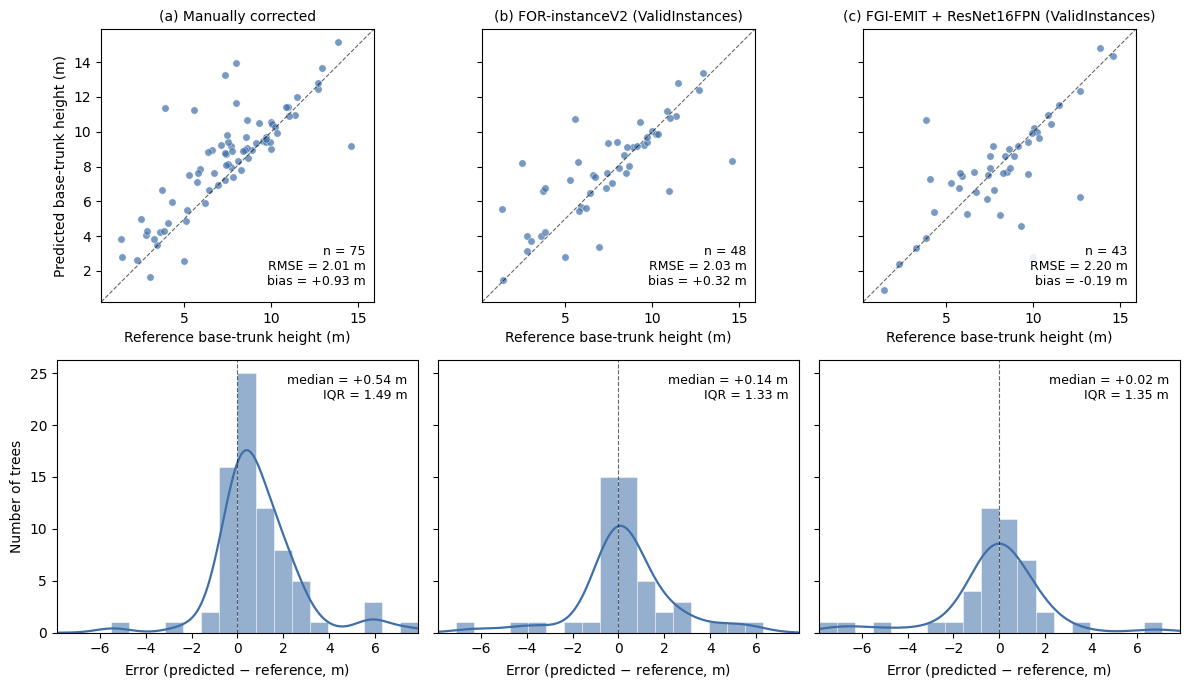

In [30]:
COLOR = "#3F6FA8"
N_BINS = 20

PANELS = [
    ("Manually corrected",                      "(a) Manually corrected"),
    ("ForestFormer3D (FOR-instanceV2)",         "(b) FOR-instanceV2 (ValidInstances)"),
    ("ForestFormer3D (FGI-EMIT) + ResNet16FPN", "(c) FGI-EMIT + ResNet16FPN (ValidInstances)"),
]

# paired_by_setting[setting] is a list of (name, pred, ref); derive arrays
data = {}
for setting, _ in PANELS:
    paired = paired_by_setting[setting]
    pred = np.array([p for _, p, _ in paired])
    ref  = np.array([r for _, _, r in paired])
    diff = pred - ref
    data[setting] = (pred, ref, diff)

all_pred = np.concatenate([d[0] for d in data.values()])
all_ref  = np.concatenate([d[1] for d in data.values()])
all_diff = np.concatenate([d[2] for d in data.values()])

lo = min(all_pred.min(), all_ref.min())
hi = max(all_pred.max(), all_ref.max())
pad = 0.05 * (hi - lo)
scatter_lim = (lo - pad, hi + pad)

diff_lim = max(abs(all_diff.min()), abs(all_diff.max())) * 1.05
bins = np.linspace(-diff_lim, diff_lim, N_BINS + 1)

fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex="row", sharey="row")

# top row: scatter
for col, (setting, title) in enumerate(PANELS):
    pred, ref, diff = data[setting]
    ax = axes[0, col]
    ax.plot(scatter_lim, scatter_lim, "k--", linewidth=0.8, alpha=0.6)
    ax.scatter(ref, pred, s=28, alpha=0.7, color=COLOR,
               edgecolor="white", linewidth=0.4)
    rmse = float(np.sqrt(np.mean(diff ** 2)))
    bias = float(np.mean(diff))
    ax.text(0.97, 0.05,
            f"n = {len(pred)}\nRMSE = {rmse:.2f} m\nbias = {bias:+.2f} m",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=9,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=3))
    ax.set_title(title, fontsize=10)
    ax.set_xlim(scatter_lim); ax.set_ylim(scatter_lim)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Reference base-trunk height (m)")
    if col == 0:
        ax.set_ylabel("Predicted base-trunk height (m)")

# bottom row: error histogram + KDE
for col, (setting, _title) in enumerate(PANELS):
    _pred, _ref, diff = data[setting]
    ax = axes[1, col]
    ax.hist(diff, bins=bins, color=COLOR, alpha=0.55,
            edgecolor="white", linewidth=0.6)
    if len(diff) >= 3 and diff.std(ddof=1) > 0:
        kde = gaussian_kde(diff)
        xs = np.linspace(bins[0], bins[-1], 400)
        bin_width = bins[1] - bins[0]
        ax.plot(xs, kde(xs) * len(diff) * bin_width, color=COLOR, linewidth=1.6)
    ax.axvline(0, color="k", linewidth=0.8, linestyle="--", alpha=0.6)
    median = float(np.median(diff))
    iqr = float(np.subtract(*np.percentile(diff, [75, 25])))
    ax.text(0.97, 0.95,
            f"median = {median:+.2f} m\nIQR = {iqr:.2f} m",
            transform=ax.transAxes, ha="right", va="top", fontsize=9,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=3))
    ax.set_xlim(-diff_lim, diff_lim)
    ax.set_xlabel("Error (predicted $-$ reference, m)")
    if col == 0:
        ax.set_ylabel("Number of trees")

fig.tight_layout()
plt.show()